# MSO203M Mini-project 1: supplied computation
**Tutorial preparation: 2 November 2026. Final submission: 4 November 2026, 23:59 IST.**

Read the Student Brief first. Your task is to choose a boundary function `g` for your assigned PDE and target. The tolerance is given. You do not need to find an optimum or write a solver.

Run the numbered steps in order, using the triangular **Run** button beside each code cell. In the input cells, change only your roll number or the formula between quotation marks. Ordinary mathematical functions are supported; the Computing Guide lists their names.

The default formula is a demonstration. It will **not** meet the required target accuracy. Replace it with the function you choose mathematically. Your Monday worksheet may contain an incomplete attempt.

This notebook contains its own numerical code. It needs NumPy and Matplotlib, both normally available in Google Colab. A local Jupyter notebook is also suitable. No GPU, paid account, external code download or Drive mounting is needed for these calculations.

## Step 1. Load the supplied tools
Run the next cell once. You do not need to edit its code. If you restart the runtime, run it again.
The formulas implemented here are explained in the Computing Guide; the report must contain your mathematical reasoning.

In [1]:
# @title Step 1: load tools (leave unchanged)
"""MSO203M mini-project 1: supplied computation, edition 2026-10-30.

Only NumPy and Matplotlib are required. All inputs are local. No network calls.
The expression reader accepts mathematical operations, not arbitrary Python.
"""
from dataclasses import dataclass, asdict
import ast
import csv
import hashlib
import json
import math
from pathlib import Path
import re
import zipfile
import numpy as np
import matplotlib.pyplot as plt

EDITION = "MSO203M-P1-2026-10-30"

@dataclass(frozen=True)
class Case:
    roll: str
    code: str
    kappa: float
    B: float
    xstar: float
    width: float
    narrow_width: float
    epsilon: float
    tutorial_factor: float
    T: float = math.log(2)

def make_case(roll):
    roll = re.sub(r"\s+", "", str(roll)).upper()
    if not re.fullmatch(r"[A-Z0-9-]{1,40}", roll):
        raise ValueError("Enter your complete roll number using letters, digits or hyphens.")
    digest = hashlib.sha256((EDITION + "|" + roll).encode("ascii")).digest()
    # Whole-roll assignment; a repeated case is permitted.
    p, q, j = [int.from_bytes(digest[i:i+2], "big") % 10 for i in (0,2,4)]
    m, n = [int.from_bytes(digest[i:i+2], "big") % 9 for i in (6,8)]
    return Case(roll, f"{p}{q}{j}{m}{n}", .5+.025*p, .075+.003*q,
                .72+.01*j, .08+.005*m, .02+.005*n, .320-.005*q, .8+.1*p)

def bump(x, centre, width):
    z = (np.asarray(x, dtype=float)-centre)/width
    return np.where(np.abs(z)<1, np.cos(np.pi*z/2)**2, 0.0)

def target(case, x, which="original"):
    width = case.width if which == "original" else case.narrow_width
    return .65*bump(x,.25,.15) + .9*bump(x,case.xstar,width)

def make_g(expression, case, which="original"):
    """Read expressions such as 0.2*sin(pi*t/T)^2. No eval is used."""
    if which not in ("original", "narrow"):
        raise ValueError("Target must be 'original' or 'narrow'.")
    if not isinstance(expression,str) or len(expression)>3000:
        raise ValueError("Enter a mathematical formula of at most 3000 characters.")
    try:
        tree = ast.parse(expression.replace("^","**"), mode="eval")
    except SyntaxError as error:
        raise ValueError("Check the formula: use * for multiplication and balanced parentheses.") from error
    width=case.width if which=="original" else case.narrow_width
    constants=dict(T=case.T,kappa=case.kappa,B=case.B,epsilon=case.epsilon,
                   xstar=case.xstar,w=width,pi=np.pi,e=np.e)
    funcs=dict(sin=np.sin,cos=np.cos,exp=np.exp,log=np.log,sqrt=np.sqrt,abs=np.abs,
               pos=lambda z: np.maximum(z,0),maximum=np.maximum,minimum=np.minimum,
               where=np.where,D=lambda z:target(case,z,which),bump=bump)
    binary={ast.Add:lambda a,b:a+b,ast.Sub:lambda a,b:a-b,ast.Mult:lambda a,b:a*b,
            ast.Div:lambda a,b:a/b,ast.Pow:lambda a,b:a**b}
    comparison={ast.Lt:np.less,ast.LtE:np.less_equal,ast.Gt:np.greater,
                ast.GtE:np.greater_equal,ast.Eq:np.equal,ast.NotEq:np.not_equal}
    if sum(1 for _ in ast.walk(tree))>600:
        raise ValueError("Please use a shorter formula.")
    def read(node,t):
        if isinstance(node,ast.Expression): return read(node.body,t)
        if isinstance(node,ast.Constant) and type(node.value) in (int,float):
            if abs(node.value)>1e6: raise ValueError("A constant in the formula is too large.")
            return float(node.value)
        if isinstance(node,ast.Name):
            if node.id in ("t","s"): return t
            if node.id in constants: return constants[node.id]
            raise ValueError("Unknown name '"+node.id+"'. See the formula guide.")
        if isinstance(node,ast.BinOp) and type(node.op) in binary:
            a,b=read(node.left,t),read(node.right,t)
            if isinstance(node.op,ast.Pow) and np.any(np.abs(b)>100):
                raise ValueError("Use an exponent between -100 and 100.")
            return binary[type(node.op)](a,b)
        if isinstance(node,ast.UnaryOp) and isinstance(node.op,(ast.UAdd,ast.USub)):
            a=read(node.operand,t)
            return a if isinstance(node.op,ast.UAdd) else -a
        if isinstance(node,ast.Call) and isinstance(node.func,ast.Name) and node.func.id in funcs and not node.keywords:
            return funcs[node.func.id](*[read(v,t) for v in node.args])
        if isinstance(node,ast.Compare):
            left=read(node.left,t); answer=True
            for op,right in zip(node.ops,node.comparators):
                if type(op) not in comparison: raise ValueError("Unsupported comparison.")
                value=read(right,t); answer=np.logical_and(answer,comparison[type(op)](left,value)); left=value
            return answer
        raise ValueError("Use only the mathematical operations listed in the guide.")
    def g(t):
        t=np.asarray(t,dtype=float)
        with np.errstate(all="ignore"):
            try: values=np.asarray(read(tree,t),dtype=float)
            except (TypeError,OverflowError,ZeroDivisionError) as error:
                raise ValueError("The formula cannot be evaluated. Check its operations and arguments.") from error
        try: values=np.broadcast_to(values,t.shape).copy()
        except ValueError as error: raise ValueError("The formula must give one value for every time.") from error
        if not np.all(np.isfinite(values)):
            raise ValueError("The formula gives an undefined/infinite value. Check divisions, logs and roots.")
        return values
    g(np.linspace(0,case.T,11))
    return g

def exact_solution(case,g,x,t):
    x=np.asarray(x,dtype=float)
    tau=np.log1p(x)
    answer=np.zeros_like(x)
    reached=t>=tau-1e-14
    if np.any(reached):
        s=np.clip(t-tau[reached],0,case.T)
        answer[reached]=(1+x[reached])**(-case.kappa)*g(s)
    return answer

def evolve(case,g,N,step_factor=.8,end_time=None):
    if type(N) is not int or not 20<=N<=2000:
        raise ValueError("Use an integer N from 20 to 2000; the required values are 100, 200 and 400.")
    if not 0<float(step_factor)<=1:
        raise ValueError("Use a step factor in (0,1]; the supplied value is 0.8.")
    end_time=case.T if end_time is None else float(end_time)
    if not 0<end_time<=case.T: raise ValueError("End time must be in (0,T].")
    h=1/N; M=math.ceil(end_time*(case.kappa+2/h)/step_factor); dt=end_time/M
    x=np.linspace(0,1,N+1); U=np.zeros(N+1); U[0]=float(g(0))
    lam=(1+x[1:])*dt/h
    # Evaluate all boundary values first: one formula entry, no coding needed.
    boundary=g(np.linspace(0,end_time,M+1))
    for n in range(M):
        U[0]=boundary[n]
        U[1:]=(1-case.kappa*dt-lam)*U[1:]+lam*U[:-1]
        U[0]=boundary[n+1]
    return x,U,M,dt

def evaluation_points(case,which,count,nodes=()):
    width=case.width if which=="original" else case.narrow_width
    extra=[0,1,.25,.25-.15,.25+.15,case.xstar,case.xstar-width,case.xstar+width]
    return np.unique(np.r_[np.linspace(0,1,count),extra,np.asarray(nodes)])

def integrate(values,points):
    return float(np.trapezoid(values,points) if hasattr(np,"trapezoid") else np.trapz(values,points))

def inspect_g(case,g,which="original",count=20001):
    t=np.linspace(0,case.T,count); values=g(t)
    x=evaluation_points(case,which,count)
    final=exact_solution(case,g,x,case.T)
    return dict(g0=float(g(0)),gT=float(g(case.T)),minimum=float(values.min()),
                maximum=float(values.max()),integral=integrate(values,t),
                design_error=float(np.max(np.abs(final-target(case,x,which)))))

def inspect_twice(case,g,which="original"):
    coarse=inspect_g(case,g,which,10001); fine=inspect_g(case,g,which,20001)
    changes={key:abs(fine[key]-coarse[key]) for key in fine}
    print("Boundary-function checks (sampled extrema and numerical integral):")
    for key in ["g0","gT","minimum","maximum","integral","design_error"]:
        print(f"  {key:14s} {fine[key]:.7f}")
    print(f"  Assigned B = {case.B:.5f}; assigned epsilon = {case.epsilon:.5f}")
    flags=[]
    if abs(fine['g0'])>1e-8 or abs(fine['gT'])>1e-8: flags.append("Endpoint values are not zero.")
    if fine['minimum'] < -1e-8: flags.append("Some sampled values of g are negative.")
    if fine['maximum'] > 1+1e-8: flags.append("Some sampled values of g exceed 1.")
    if fine['integral']>case.B+1e-8: flags.append("The estimated integral exceeds B.")
    if fine['design_error']>case.epsilon+1e-8: flags.append("The estimated exact design error exceeds epsilon.")
    for message in flags: print("  CHECK: "+message)
    if not flags: print("  No violation detected on these samples. Supply your mathematical justification.")
    print(f"  Largest change on doubling the checking grid: {max(changes.values()):.3g}")
    if max(changes.values())>1e-4: print("  Values are sensitive to sampling. Refine the checking grid and inspect the formula.")
    print("  Continuity, piecewise differentiability and bounds between samples require mathematical checking.")
    return fine,changes

def run_experiment(case,expression,which="original",grids=(100,200,400),step_factor=.8,folder="project_results",show=True):
    if which not in ("original","narrow"): raise ValueError("Choose original or narrow.")
    folder=Path(folder); folder.mkdir(parents=True,exist_ok=True)
    g=make_g(expression,case,which)
    checks,changes=inspect_twice(case,g,which)
    rows=[]; curves=[]
    for N in grids:
        x,U,M,dt=evolve(case,g,int(N),step_factor)
        errors=[]
        for count in (10001,20001):
            xx=evaluation_points(case,which,count,x)
            truth=exact_solution(case,g,xx,case.T); interp=np.interp(xx,x,U)
            errors.append((float(np.max(np.abs(truth-target(case,xx,which)))),
                           float(np.max(np.abs(interp-truth))),
                           float(np.max(np.abs(interp-target(case,xx,which))))))
        E,delta,comp=errors[-1]
        change=max(abs(a-b) for a,b in zip(errors[0],errors[1]))
        row=dict(roll=case.roll,case_code=case.code,target=which,width=case.width if which=="original" else case.narrow_width,
                 epsilon=case.epsilon,N=int(N),M=M,dt=dt,E=E,delta_num=delta,E_comp=comp,
                 integral_g=checks['integral'],max_g=checks['maximum'],sample_change=change)
        rows.append(row); curves.append((int(N),x,U))
    print("\nNumerical comparison: same boundary function on every grid")
    print("   N      M       E(g)      delta_num    E_comp")
    for row in rows: print(f"{row['N']:4d} {row['M']:6d}   {row['E']:.6f}    {row['delta_num']:.6f}    {row['E_comp']:.6f}")
    print("E(g) is the exact-solution discrepancy. Refining the PDE grid changes the last two columns.")
    print("E_comp may exceed epsilon even when the chosen g satisfies the design requirement.")
    print("All reported maxima are estimates of continuous maxima, using linear interpolation for U.")
    print(f"Largest error-estimate change after doubling evaluation points: {max(r['sample_change'] for r in rows):.3g}")
    xx=evaluation_points(case,which,4001)
    tt=np.linspace(0,case.T,4001)
    fig,axes=plt.subplots(1,2,figsize=(11,3.6),layout="constrained")
    axes[0].plot(tt,g(tt),color="black",lw=1.5,label="chosen g")
    axes[0].axhline(1,color=".5",ls=":",lw=1,label="upper bound 1")
    axes[0].set(xlabel="t",ylabel="g(t)",title="Boundary function")
    axes[0].legend(fontsize=8)
    axes[1].plot(xx,target(case,xx,which),color="black",lw=2,label="D (target)")
    axes[1].plot(xx,exact_solution(case,g,xx,case.T),color=".4",lw=1.8,ls="--",label="exact u_g at T")
    for (N,x,U),style in zip(curves,[":","-.",(0,(5,2,1,2))]):
        axes[1].plot(x,U,color="black",lw=1,ls=style,label=f"numerical N={N}")
    axes[1].set(xlabel="x",ylabel="value",title=f"{which.capitalize()} target; case {case.code}")
    axes[1].legend(fontsize=7,loc="upper left")
    for ax in axes: ax.spines[['top','right']].set_visible(False)
    fig.savefig(folder/f"{which}_comparison.png",dpi=180)
    fig.savefig(folder/f"{which}_comparison.pdf")
    if show: plt.show()
    else: plt.close(fig)
    return dict(edition=EDITION,case=asdict(case),expression=expression,target=which,
                checking_points=20001,checks=checks,checking_changes=changes,rows=rows)

def show_case(case,folder="project_results",show=True):
    folder=Path(folder); folder.mkdir(parents=True,exist_ok=True)
    print("Assigned data -- copy these onto your preparation sheet")
    for key in ['roll','code','kappa','B','xstar','width','narrow_width','epsilon','T','tutorial_factor']:
        value = getattr(case,key)
        displayed = f"{value:.6f}" if isinstance(value,float) else value
        print(f"{key:18s}: {displayed}")
    print("width = w; narrow_width = w_n; tutorial_factor = lambda.")
    print("tutorial_factor is a supplied number for the tutorial; it is not a restriction on g.")
    (folder/'assigned_data.json').write_text(json.dumps(asdict(case),indent=2))
    fig,ax=plt.subplots(figsize=(8,3.2),layout="constrained")
    x=np.linspace(0,1,2001)
    ax.plot(x,target(case,x),color='black',lw=2,label='original D')
    ax.plot(x,target(case,x,'narrow'),color='.5',ls='--',label='narrower D')
    ax.set(xlabel='x',ylabel='target value',title=f'Your targets: {case.roll}, case {case.code}')
    ax.legend(); ax.spines[['top','right']].set_visible(False)
    fig.savefig(folder/'assigned_targets.png',dpi=180)
    if show: plt.show()
    else: plt.close(fig)
    fig,ax=plt.subplots(figsize=(8.27,11.69)); ax.axis('off')
    lines=['MSO203M Mini-project 1: assigned data',f'Roll number: {case.roll}    Case: {case.code}',
           '',f'kappa = {case.kappa:.5f}',f'B = {case.B:.5f}',f'x_* = {case.xstar:.5f}',
           f'w = {case.width:.5f}',f'w_narrow = {case.narrow_width:.5f}',
           f'epsilon = {case.epsilon:.5f}',f'T = log(2) = {case.T:.7f}',
           f'Tutorial factor lambda = {case.tutorial_factor:.2f}',
           f'R_star = (1+x_*)^(-kappa) = {(1+case.xstar)**(-case.kappa):.7f}',
           '', 'Use the Preparation Sheet for your own working.',
           'Tutorial: 2 November 2026. Final submission: 4 November 2026.']
    ax.text(.06,.95,'\n'.join(lines),va='top',fontsize=12,linespacing=1.65)
    fig.savefig(folder/'assigned_data.pdf'); plt.close(fig)

def export_results(case,runs,folder="project_results"):
    folder=Path(folder); folder.mkdir(parents=True,exist_ok=True)
    if not runs: raise ValueError("Run at least one experiment before exporting.")
    if any(run['case']!=asdict(case) for run in runs):
        raise ValueError("Some results belong to different assigned data. Rerun all steps for your roll number.")
    records=[row for run in runs for row in run['rows']]
    with (folder/'results.csv').open('w',newline='') as handle:
        writer=csv.DictWriter(handle,fieldnames=list(records[0])); writer.writeheader(); writer.writerows(records)
    (folder/'run_record.json').write_text(json.dumps(runs,indent=2))
    fig,ax=plt.subplots(figsize=(8.27,11.69)); ax.axis('off')
    head=[f'MSO203M: results summary for {case.roll}',f'Case {case.code}; kappa={case.kappa:.3f}; B={case.B:.3f}; epsilon={case.epsilon:.3f}',
          f'x_*={case.xstar:.2f}; widths={case.width:.3f}, {case.narrow_width:.3f}',
          'Maxima and integrals below are numerical estimates.']
    ax.text(.03,.97,'\n'.join(head),va='top',fontsize=11,linespacing=1.5)
    y=.83
    import textwrap
    for run in runs:
        display_expression=run['expression'] if len(run['expression'])<=280 else run['expression'][:260]+' ... [full formula in run_record.json]'
        text=[run['target'].upper()+' TARGET', 'g(t) = '+display_expression,
              f"g(0)={run['checks']['g0']:.5g}, g(T)={run['checks']['gT']:.5g}, min g={run['checks']['minimum']:.5g}",
              f"max g={run['checks']['maximum']:.6f}; integral g={run['checks']['integral']:.6f}",
              'N       E(g)          delta_num       E_comp']
        text += [f"{r['N']:<5}   {r['E']:.6f}       {r['delta_num']:.6f}       {r['E_comp']:.6f}" for r in run['rows']]
        wrapped=[]
        for line in text: wrapped.extend(textwrap.wrap(line,width=77,break_long_words=True) or [''])
        ax.text(.03,y,'\n'.join(wrapped),va='top',fontsize=9.5,family='monospace',linespacing=1.55)
        y-=.37
    ax.text(.03,.055,'Add your mathematical justification and interpretation in the report.\nThis summary is not a proof of the constraints.',va='bottom',fontsize=10)
    fig.savefig(folder/'results_summary.pdf'); plt.close(fig)
    archive=folder.parent/f'MSO203M_{case.roll}_results.zip'
    with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
        names=['assigned_data.json','assigned_data.pdf','assigned_targets.png','results.csv','run_record.json','results_summary.pdf']
        for run in runs: names.extend([run['target']+'_comparison.png',run['target']+'_comparison.pdf'])
        for name in sorted(set(names)):
            path=folder/name
            if path.is_file(): z.write(path,path.name)
    print(f'Created {archive.name}. Download it together with your completed notebook.')
    return str(archive)

print("Tools loaded. Continue to Step 2.")

Tools loaded. Continue to Step 2.


## Step 2. Enter your complete roll number
Replace `EXAMPLE` below with your complete roll number, keeping the quotation marks. Run the cell. It prints your assigned values, displays both targets and creates a printable data page.

Use these generated values throughout the project. Do not change the assigned coefficients or the budget/tolerance pairing. If you change the roll number, rerun Steps 2–5.

Assigned data -- copy these onto your preparation sheet
roll              : 250120
code              : 16931
kappa             : 0.525000
B                 : 0.093000
xstar             : 0.810000
width             : 0.095000
narrow_width      : 0.025000
epsilon           : 0.290000
T                 : 0.693147
tutorial_factor   : 0.900000
width = w; narrow_width = w_n; tutorial_factor = lambda.
tutorial_factor is a supplied number for the tutorial; it is not a restriction on g.


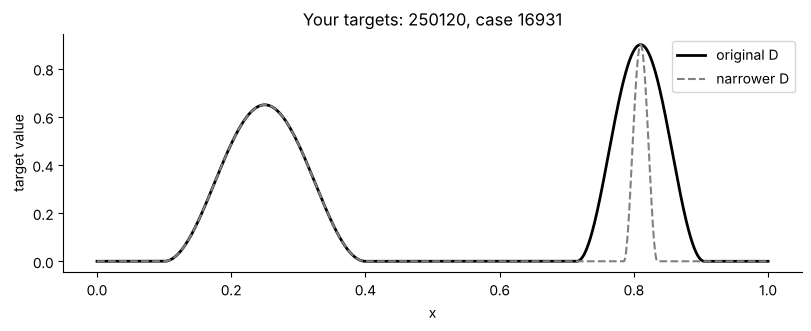

R_star = (1+xstar)^(-kappa) = 0.7323501


In [2]:
# @title Step 2: your assigned data
roll_number = "250120" # @param {type:"string"}
case = make_case(roll_number)
results_folder = "project_results_" + case.roll
original_run = None
narrow_run = None
show_case(case, results_folder)
print("R_star = (1+xstar)^(-kappa) =", round((1+case.xstar)**(-case.kappa),7))

## Step 3. Test your proposed boundary function for the original target
Replace the formula below with your chosen $g(t)$. The demonstration $0.2sin^2(pi t/T)$ is an example of the input syntax, not a solution of the design task.

Use `*` for multiplication and `^` for powers. Available names are `t` (or `s`), `T`, `kappa`, `B`, `epsilon`, `xstar`, `w`, `pi`, `e`. Available functions include `sin`, `cos`, `exp`, `log`, `sqrt`, `abs`, `pos`, `maximum`, `minimum`, `where`, `D`, `bump`. For example, `pos(z)` means $max(z,0)$, and `D(z)` means the assigned target evaluated at position $z$.

The cell checks your formula, runs the supplied method for $N=100,200,400$, and plots the results. Redesign $g$ mathematically if a restriction fails. A warning about the demonstration formula is expected.

All maxima and integrals printed by the program are **numerical estimates**. The code does not prove continuity or bounds between samples. Give mathematical justification in the report. An error between the computed curve and $D$ exceeding `epsilon` does not by itself invalidate your exact design.

Boundary-function checks (sampled extrema and numerical integral):
  g0             0.0000000
  gT             0.0000000
  minimum        0.0000000
  maximum        0.8848907
  integral       0.0837016
  design_error   0.2600000
  Assigned B = 0.09300; assigned epsilon = 0.29000
  No violation detected on these samples. Supply your mathematical justification.
  Largest change on doubling the checking grid: 2.03e-09
  Continuity, piecewise differentiability and bounds between samples require mathematical checking.

Numerical comparison: same boundary function on every grid
   N      M       E(g)      delta_num    E_comp
 100    174   0.260000    0.375873    0.627729
 200    348   0.260000    0.289300    0.541155
 400    694   0.260000    0.198831    0.450746
E(g) is the exact-solution discrepancy. Refining the PDE grid changes the last two columns.
E_comp may exceed epsilon even when the chosen g satisfies the design requirement.
All reported maxima are estimates of continuous maxima, u

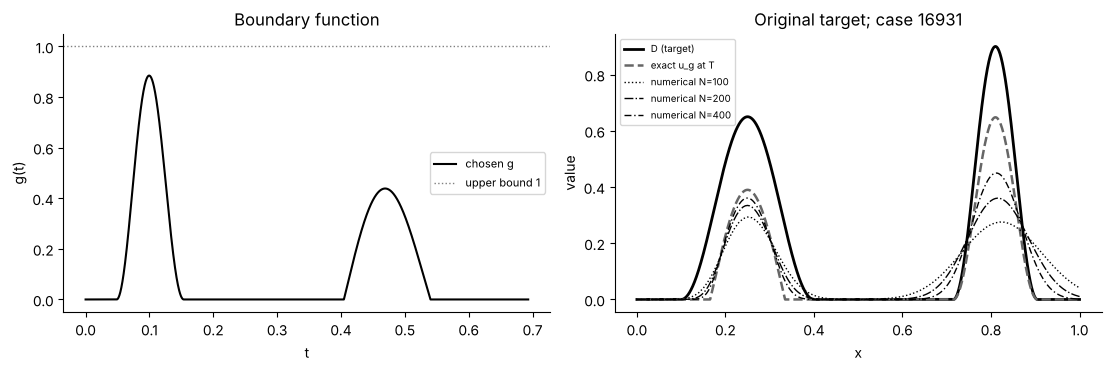

In [3]:
# @title Step 3: original-target experiment
g_original = "(2*exp(-t))^kappa*(pos(0.65*bump(2*exp(-t)-1,0.25,0.15)-0.26)+0.72*0.9*bump(2*exp(-t)-1,xstar,w))" # @param {type:"string"}
original_run = run_experiment(case, g_original, "original", (100,200,400), folder=results_folder)

## Step 4. The narrower target (complete after Monday if necessary)
First write your prediction in your notes: how might narrowing the second peak affect the required boundary function and the numerical approximation?

Enter your chosen function for the narrower target. In this cell `D(z)` and `w` refer to the **narrower** target. All other assigned data, including `epsilon`, are unchanged. You may reuse the algebraic form of a construction, but check it for the new target. Merely keeping an arbitrary original $g$ is not guaranteed to work.

This cell runs $N=100,400$. Compare the two types of target on matching grids. Do not force the observations to agree with your prediction: explain what the results show.

Boundary-function checks (sampled extrema and numerical integral):
  g0             0.0000000
  gT             0.0000000
  minimum        0.0000000
  maximum        0.8848254
  integral       0.0648729
  design_error   0.2600000
  Assigned B = 0.09300; assigned epsilon = 0.29000
  No violation detected on these samples. Supply your mathematical justification.
  Largest change on doubling the checking grid: 1.16e-10
  Continuity, piecewise differentiability and bounds between samples require mathematical checking.

Numerical comparison: same boundary function on every grid
   N      M       E(g)      delta_num    E_comp
 100    174   0.260000    0.571128    0.823126
 400    694   0.260000    0.496056    0.748051
E(g) is the exact-solution discrepancy. Refining the PDE grid changes the last two columns.
E_comp may exceed epsilon even when the chosen g satisfies the design requirement.
All reported maxima are estimates of continuous maxima, using linear interpolation for U.
Largest error-

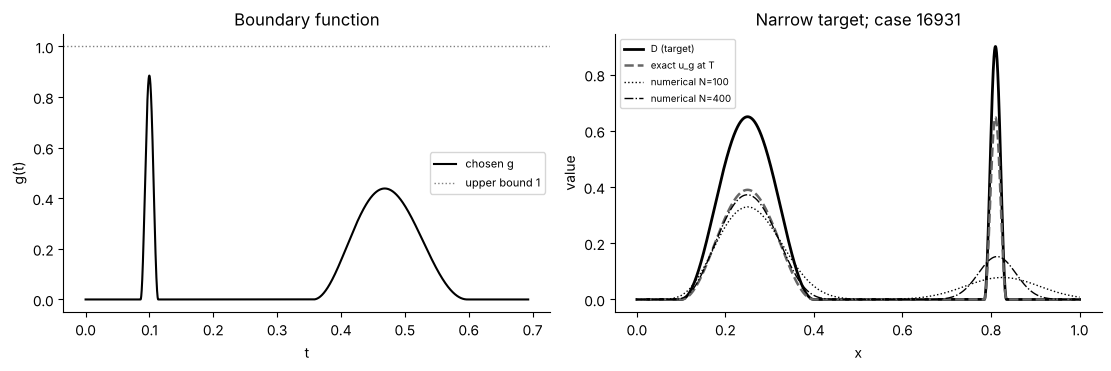

In [4]:
# @title Step 4: narrower-target experiment
g_narrow = "(2*exp(-t))^kappa*(0.6*0.65*bump(2*exp(-t)-1,0.25,0.15)+0.72*0.9*bump(2*exp(-t)-1,xstar,w))" # @param {type:"string"}
narrow_run = run_experiment(case, g_narrow, "narrow", (100,400), folder=results_folder)

## Step 5. Export your results
Run this after the experiments you want to save. The ZIP contains assigned data, comparison figures, a CSV table, the formulas/settings in JSON, and a printable results summary. If only Step 3 is complete, it exports that initial attempt.

In Colab the download should start automatically. If it does not, open the Files panel, find the ZIP, and choose Download. Separately download this completed notebook from the File menu in `.ipynb` format. Keep its output cells. Submit your report, completed notebook and results ZIP through the project submission link announced on Hello-IITK.

If you change a formula, rerun that experiment and export again. Downloading the notebook alone does not include the separate files in the runtime.

In [5]:
# @title Step 5: export results
completed_runs = [r for r in (original_run, narrow_run) if r is not None]
archive_path = export_results(case, completed_runs, results_folder)
try:
    from google.colab import files
except ImportError:
    print("Download/open the archive from the folder shown above.")
else:
    files.download(archive_path)

Created MSO203M_250120_results.zip. Download it together with your completed notebook.
Download/open the archive from the folder shown above.


## What to write in your report
Use the four parts A–D in the brief. Explain your characteristic solution, your choice of boundary function, the restrictions and tolerance, the supplied update rule, and the experimental comparisons. Plots need an interpretation. Do not submit a transcript of an AI conversation.

The program's `E` column estimates the discrepancy of the **exact characteristic solution** from the target. `delta_num` estimates the discrepancy of the **computed curve** from that exact solution. `E_comp` estimates the discrepancy of the computed curve from the target. The supplied method uses linear interpolation between its spatial grid values when these errors are measured.

Technical help with Colab: https://research.google.com/colaboratory/faq.html